# 06 · Overfitting: to the images, or to the hospital?

"Overfitting" means two different things here, and they need different remedies:

| | Overfitting to the **training images** | Overfitting to the **source dataset** |
|---|---|---|
| symptom | training loss ≪ validation loss | validation loss ≪ Kermany-test / RSNA loss |
| visible on Kermany validation? | yes | **no**: validation shares the source's quirks |
| controlled by | early stopping, weight decay, dropout | variation the model cannot exploit: augmentation, multi-source data |
| status after E1 | contained (early stopping, val AUROC 0.99) | **severe**: loss 10–17× higher out of distribution |

This notebook first measures both kinds for every configuration, then tests five interventions built on E2. Each targets a specific mechanism identified in notebooks 01 and 05:

| Variant | What is added to E2 | Hypothesis it tests |
|---|---|---|
| **E2_ACQ** | random blur (σ 0.3–1.5 px), sensor-like noise, down/up-sampling to 35–70% resolution | Kermany's classes differ in resolution and JPEG quality. Randomising sharpness and noise should weaken that shortcut and improve RSNA |
| **E2_ERASE** | random erasing of a 2–12% rectangle + random masking of a 3–12% border frame | models attend to the image periphery (markers, collimation, shoulders). Occluding it should push evidence into the lungs |
| **E2_ROBUST** | ACQ + ERASE | are the two complementary? |
| **E2_MIX** | mixup (α = 0.4): train on convex combinations of image pairs and their labels | out-of-distribution failure is *over-confident*. Mixup is known to regularise confidence and improve calibration |
| **LP** | frozen ImageNet backbone, only the linear head is trained (+ E2 augmentation) | if most of the damage is the network *re-learning* Kermany-specific features, a frozen generic representation should transfer better, at the price of in-domain fit |

Rules are unchanged: the same 1,000 images, step budget and early stopping, Kermany validation for checkpoint and threshold, three seeds. LP uses its own fixed head-only optimiser settings (lr 5·10⁻³, cosine), since a single linear layer trains very differently from a full network. Architectures: all seven from notebook 03.

External numbers: RSNA is split by patient into **RSNA-dev** (30%, used only to choose between configurations) and **RSNA-test** (70%,
reporting). The ladder and calibration use all labelled RSNA images; comparisons between variants are reported on RSNA-test.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "reports/results"; RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

import torch
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, log_loss
from cxr.analysis import collect_runs, mean_sd, compare, strata_runs, ece, EVAL_LABELS, STRATA_LABELS, ROLE_LABELS
from cxr.engine import load_model, predict_logits, get_device, sigmoid, RUNS_DIR
from cxr.data import load_set, read_manifest, ensure_cache
from cxr.explain import gradcam

EXPS = ["E1", "E2", "E2_ACQ", "E2_ERASE", "E2_ROBUST", "E2_MIX", "LP"]
ARCHS = ["efficientnet_b0", "densenet121", "vit_small", "resnet18", "resnet50", "convnext_tiny", "swin_tiny"]
A = "artifacts/manifests/kermany.csv"
ALL_LABELS = {**EVAL_LABELS, **STRATA_LABELS, **ROLE_LABELS}
DELTA_KEYS = ["A_test:label", "B_external:label@b_role=test", "B_external:label@view=PA", "B_external:label@view=AP"]
runs = collect_runs()
runs = runs[runs.experiment.isin(EXPS) & runs.arch.isin(ARCHS)]
print(runs.drop_duplicates(["experiment", "arch", "seed"]).groupby(["arch", "experiment"]).size().unstack())
device = get_device()

/home/edelweizse/Projects/uni/AIE/final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


experiment       E1  E2  E2_ACQ  E2_ERASE  E2_MIX  E2_ROBUST  LP
arch                                                            
convnext_tiny     3   3       3         3       3          3   3
densenet121       3   3       3         3       3          3   3
efficientnet_b0   3   3       3         3       3          3   3
resnet18          3   3       3         3       3          3   3
resnet50          3   3       3         3       3          3   3
swin_tiny         3   3       3         3       3          3   3
vit_small         3   3       3         3       3          3   3


## 1. The loss ladder: train → validation → Kermany test → RSNA

For every run: BCE and AUROC on its own 1,000 training images (no augmentation), Kermany validation, Kermany test and RSNA (opacity vs normal), all at the selected checkpoint. A healthy model has a short ladder. Large jumps between validation and the test sets are dataset-level overfitting that validation cannot see.

In [2]:
cache = RES / "overfitting_ladder.csv"
done = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=["experiment", "arch", "seed"])
have = set(map(tuple, done[["experiment", "arch", "seed"]].astype(str).values))
train_set = load_set(A, {"split": "train", "subset_rank": {"lt": 500}}, 224, "squash", device=None)
rows = []
for (exp, arch, seed), _ in runs.groupby(["experiment", "arch", "seed"]):
    if (exp, arch, str(seed)) in have:
        continue
    rd = RUNS_DIR / exp / arch / f"seed{seed}"
    model, _ = load_model(rd, device)
    y = train_set.labels.numpy(); p = sigmoid(predict_logits(model, train_set, device, 256))
    r = {"experiment": exp, "arch": arch, "seed": seed, "train_bce": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)), "train_auroc": roc_auc_score(y, p)}
    for name, f, col in [("val", "preds_val.csv", "label"), ("testA", "preds_A_test.csv", "label"), ("B", "preds_B_external.csv", "label")]:
        d = pd.read_csv(rd / f); d = d[d[col].notna()]
        r[f"{name}_bce"] = log_loss(d[col], np.clip(d.prob, 1e-7, 1 - 1e-7)); r[f"{name}_auroc"] = roc_auc_score(d[col], d.prob)
    rows.append(r)
    pd.concat([done, pd.DataFrame(rows)], ignore_index=True).to_csv(cache, index=False)  # resumable: saved after every run
    del model; torch.cuda.empty_cache()
ladder = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
ladder["seed"] = ladder.seed.astype(int)
ladder.to_csv(cache, index=False)
lad = ladder.groupby(["arch", "experiment"])[[c for c in ladder if c.endswith(("_bce", "_auroc"))]].mean()
lad["RSNA/val loss ratio"] = lad.B_bce / lad.val_bce
display(lad.reindex(pd.MultiIndex.from_product([ARCHS, EXPS])).dropna(how="all").round(3))

train_bce  train_auroc  val_bce  val_auroc  testA_bce  testA_auroc  B_bce  B_auroc  RSNA/val loss ratio
efficientnet_b0 E1             0.011        1.000    0.044      0.999      0.588        0.937  0.767    0.859               17.457
                E2             0.011        1.000    0.058      0.997      0.453        0.932  0.511    0.915                8.875
                E2_ACQ         0.010        1.000    0.061      0.998      0.482        0.950  0.642    0.908               10.472
                E2_ERASE       0.007        1.000    0.063      0.998      0.440        0.955  0.652    0.920               10.367
                E2_ROBUST      0.009        1.000    0.069      0.997      0.581        0.955  0.786    0.909               11.375
                E2_MIX         0.038        1.000    0.067      0.998      0.408        0.958  0.451    0.895                6.731
                LP             0.075        0.999    0.120      0.992      0.341        0.957  0.662    0.782                5.540
densenet121     E1             0.006        1.000    0.044      0.999      0.597        0.932  0.761    0.883               17.245
                E2             0.005        1.000    0.052      0.998      0.430        0.947  0.540    0.915               10.450
                E2_ACQ         0.043        0.998    0.075      0.996      0.491        0.951  0.612    0.888                8.115
                E2_ERASE       0.039        0.999    0.079      0.996      0.431        0.972  0.660    0.924                8.393
                E2_ROBUST      0.039        0.998    0.080      0.996      0.355        0.970  0.553    0.894                6.920
                E2_MIX         0.027        1.000    0.066      0.998      0.372        0.968  0.416    0.922                6.315
                LP             0.057        0.998    0.104      0.992      0.413        0.958  1.112    0.827               10.647
vit_small       E1             0.017        1.000    0.079      0.995      0.695        0.866  1.359    0.823               17.154
                E2             0.040        0.999    0.088      0.994      0.436        0.926  0.654    0.867                7.473
                E2_ACQ         0.038        1.000    0.092      0.996      0.382        0.957  0.623    0.885                6.778
                E2_ERASE       0.021        1.000    0.085      0.997      0.420        0.956  0.537    0.919                6.295
                E2_ROBUST      0.033        1.000    0.087      0.996      0.423        0.951  0.676    0.908                7.728
                E2_MIX         0.035        1.000    0.074      0.997      0.438        0.884  0.436    0.889                5.931
                LP             0.101        0.997    0.106      0.994      0.363        0.960  0.951    0.797                8.938
resnet18        E1             0.016        1.000    0.063      0.998      0.398        0.945  0.582    0.876                9.212
                E2             0.017        1.000    0.068      0.997      0.382        0.939  0.483    0.906                7.061
                E2_ACQ         0.019        1.000    0.078      0.997      0.347        0.958  0.471    0.903                6.049
                E2_ERASE       0.017        1.000    0.082      0.996      0.368        0.930  0.476    0.911                5.796
                E2_ROBUST      0.027        1.000    0.078      0.995      0.346        0.942  0.524    0.898                6.747
                E2_MIX         0.047        1.000    0.091      0.998      0.338        0.949  0.426    0.892                4.699
                LP             0.129        0.995    0.153      0.985      0.359        0.955  0.862    0.814                5.639
resnet50        E1             0.002        1.000    0.055      0.998      0.591        0.947  0.942    0.865               17.280
                E2             0.003        1.000    0.052      0.998      0.502        0.967  0.

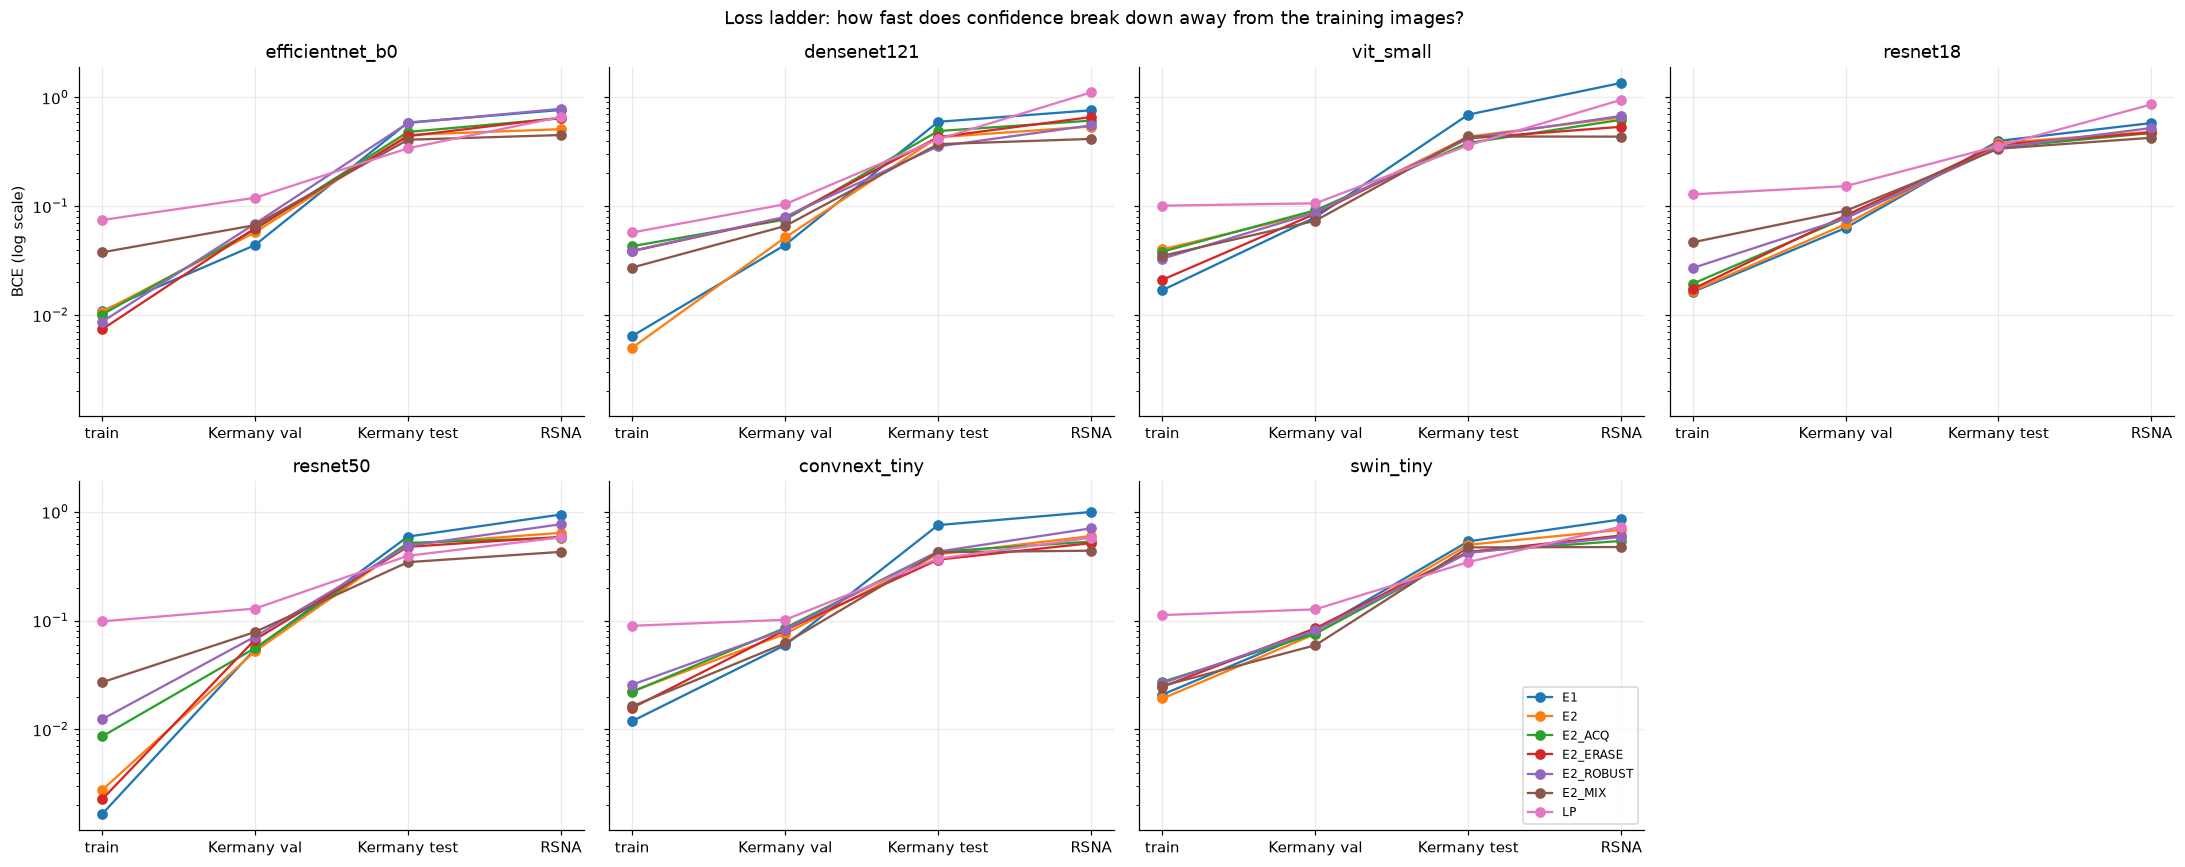

In [3]:
ncol = 4
fig, axes = plt.subplots(-(-len(ARCHS) // ncol), ncol, figsize=(5 * ncol, 4 * -(-len(ARCHS) // ncol)), sharey=True, squeeze=False)
axes = axes.ravel()
for ax in axes[len(ARCHS):]:
    ax.axis("off")
axes = axes[:len(ARCHS)]
stages = ["train_bce", "val_bce", "testA_bce", "B_bce"]
for ax, arch in zip(axes, ARCHS):
    for exp in EXPS:
        if (arch, exp) in lad.index:
            ax.plot(range(4), lad.loc[(arch, exp), stages], marker="o", label=exp)
    ax.set_xticks(range(4), ["train", "Kermany val", "Kermany test", "RSNA"]); ax.set_yscale("log"); ax.set_title(arch)
axes[0].set_ylabel("BCE (log scale)"); axes[-1].legend(fontsize=8)
fig.suptitle("Loss ladder: how fast does confidence break down away from the training images?")
plt.tight_layout(); plt.savefig(FIG / "overfitting_ladder.png", bbox_inches="tight"); plt.show()

**How to read it.** The step from *train* to *Kermany val* is classic overfitting to the training images. The steps from *Kermany val* to *Kermany test* and *RSNA* are overfitting to the dataset. Note the log scale: one grid line is a factor of 10.

## 2. Discrimination: AUROC on every test view

In [4]:
strata = strata_runs(runs, {**STRATA_LABELS, **ROLE_LABELS})
tabs = []
for key, lab in EVAL_LABELS.items():
    tabs.append(mean_sd(runs[runs["eval"] == key], ["arch", "experiment"], ["auroc"]).drop(columns="seeds").rename(columns={"auroc": lab}))
for key, lab in {**STRATA_LABELS, **ROLE_LABELS}.items():
    tabs.append(mean_sd(strata[strata["eval"] == key], ["arch", "experiment"], ["auroc"]).drop(columns="seeds").rename(columns={"auroc": lab}))
auc_table = pd.concat(tabs, axis=1).reindex(pd.MultiIndex.from_product([ARCHS, EXPS])).dropna(how="all")
auc_table.to_csv(RES / "overfitting_variants_auroc.csv")
display(auc_table)

Kermany test (internal) RSNA: opacity vs normal RSNA: opacity vs all RSNA PA only: opacity vs normal RSNA AP only: opacity vs normal  \
efficientnet_b0 E1                  0.937 ± 0.005           0.859 ± 0.004        0.736 ± 0.002                   0.767 ± 0.019                   0.707 ± 0.029   
                E2                  0.932 ± 0.032           0.915 ± 0.010        0.778 ± 0.015                   0.843 ± 0.011                   0.830 ± 0.060   
                E2_ACQ              0.950 ± 0.014           0.908 ± 0.008        0.782 ± 0.009                   0.805 ± 0.003                   0.848 ± 0.037   
                E2_ERASE            0.955 ± 0.016           0.920 ± 0.001        0.788 ± 0.004                   0.845 ± 0.005                   0.859 ± 0.010   
                E2_ROBUST           0.955 ± 0.007           0.909 ± 0.014        0.779 ± 0.013                   0.832 ± 0.009                   0.815 ± 0.057   
                E2_MIX              0.958 ± 0.013           0.895 ± 0.009        0.762 ± 0.014                   0.799 ± 0.003                   0.813 ± 0.036   
                LP                  0.957 ± 0.001           0.782 ± 0.004        0.683 ± 0.003                   0.705 ± 0.004                   0.603 ± 0.006   
densenet121     E1                  0.932 ± 0.020           0.883 ± 0.017        0.755 ± 0.016                   0.811 ± 0.014                   0.764 ± 0.028   
                E2                  0.947 ± 0.018           0.915 ± 0.011        0.778 ± 0.013                   0.854 ± 0.010                   0.819 ± 0.046   
                E2_ACQ              0.951 ± 0.021           0.888 ± 0.030        0.765 ± 0.025                   0.783 ± 0.051                   0.792 ± 0.081   
                E2_ERASE            0.972 ± 0.008           0.924 ± 0.011        0.790 ± 0.010                   0.854 ± 0.026                   0.861 ± 0.010   
                E2_ROBUST           0.970 ± 0.009           0.894 ± 0.025        0.771 ± 0.021                   0.795 ± 0.055                   0.799 ± 0.056   
                E2_MIX              0.968 ± 0.010           0.922 ± 0.003        0.792 ± 0.004                   0.839 ± 0.013                   0.871 ± 0.003   
                LP                  0.958 ± 0.002           0.827 ± 0.016        0.704 ± 0.012                   0.751 ± 0.008                   0.790 ± 0.006   
vit_small       E1                  0.866 ± 0.075           0.823 ± 0.016        0.711 ± 0.016                   0.707 ± 0.007                   0.675 ± 0.041   
                E2                  0.926 ± 0.040           0.867 ± 0.062        0.745 ± 0.040                   0.757 ± 0.092                   0.786 ± 0.081   
                E2_ACQ              0.957 ± 0.031           0.885 ± 0.010        0.753 ± 0.005                   0.790 ± 0.022                   0.786 ± 0.016   
                E2_ERASE            0.956 ± 0.011           0.919 ± 0.006        0.786 ± 0.010                   0.842 ± 0.012                   0.856 ± 0.028   
                E2_ROBUST           0.951 ± 0.023           0.908 ± 0.014        0.771 ± 0.008                   0.827 ± 0.025                   0.830 ± 0.028   
                E2_MIX              0.884 ± 0.042           0.889 ± 0.004        0.754 ± 0.006                   0.811 ± 0.011                   0.767 ± 0.038   
                LP                  0.960 ± 0.001           0.797 ± 0.006        0.699 ± 0.009                   0.671 ± 0.025                   0.683 ± 0.004   
resnet18        E1                  0.945 ± 0.005           0.876 ± 0.032        0.750 ± 0.027                   0.798 ± 0.021                   0.741 ± 0.072   
                E2                  0.939 ± 0.013           0.906 ± 0.009        0.768 ± 0.008                   0.841 ± 0.005                   0.795 ± 0.034   
                E2_ACQ              0.958 ± 0.009           0.903 ± 0.014        0.776 ± 0.014                   0.812 ± 0.018            

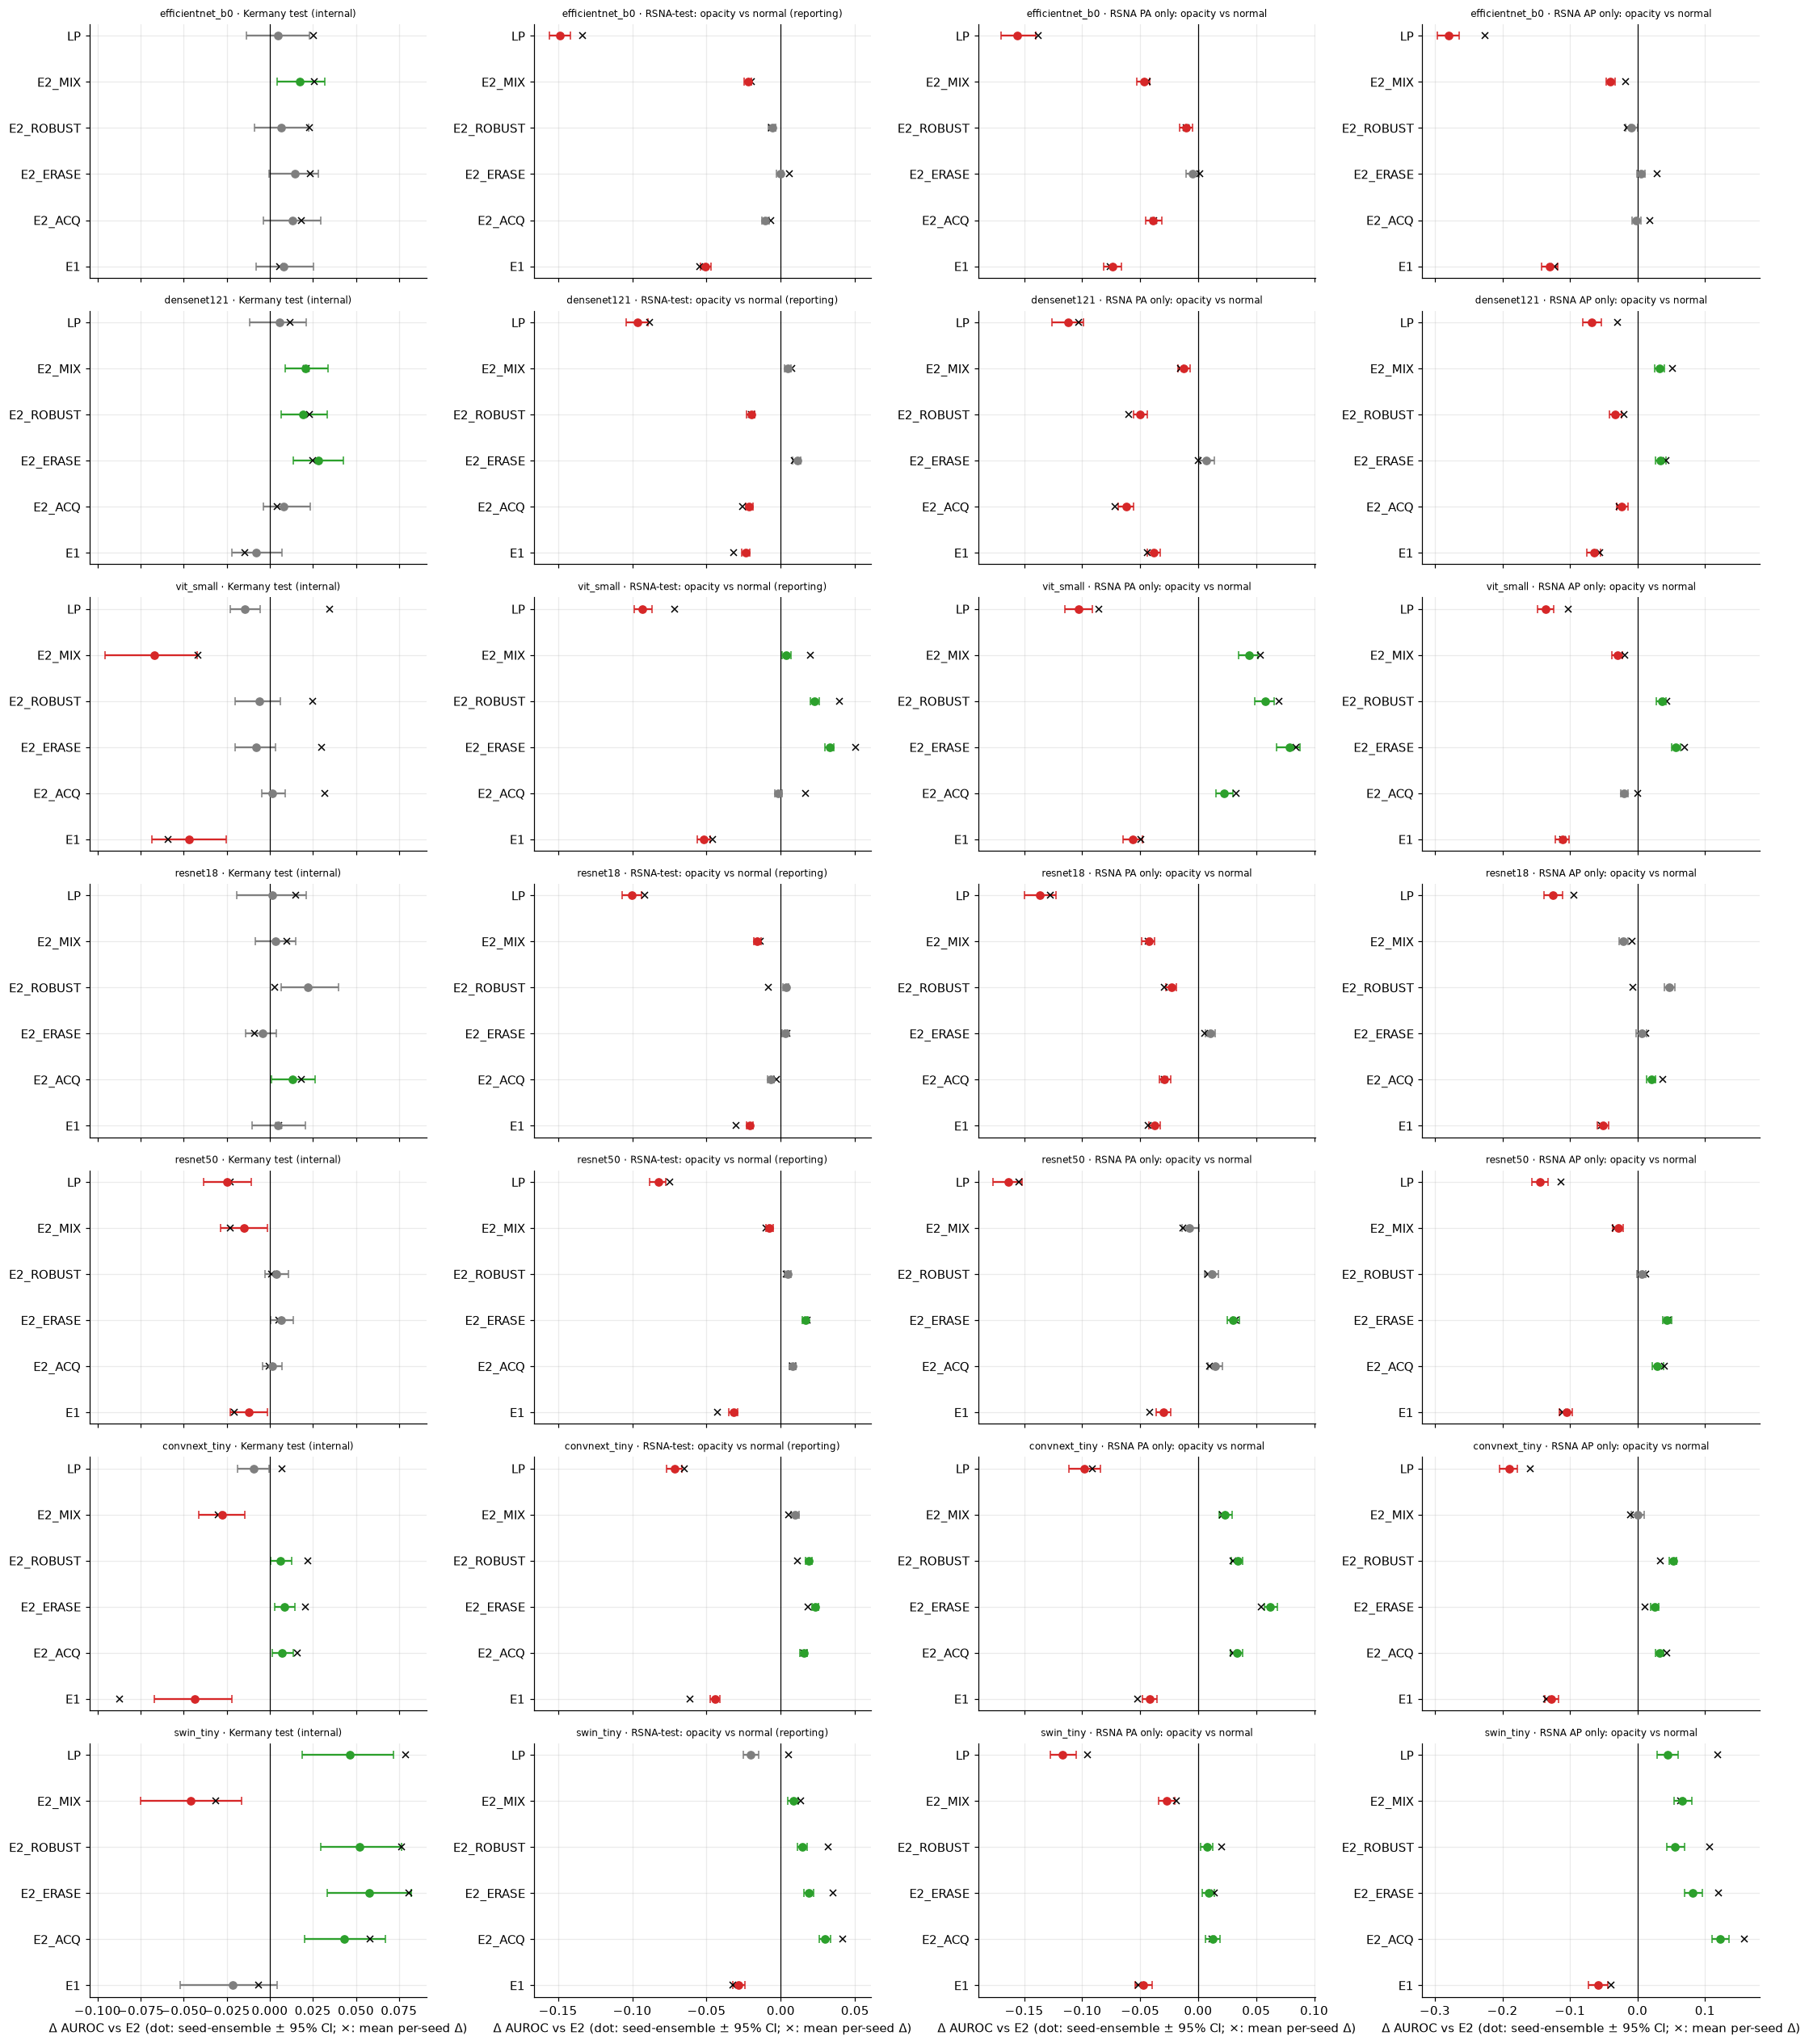

In [5]:
rows = [compare("E2", e, arch, key, n_boot=500) for arch in ARCHS for e in EXPS if e not in ("E2",) for key in DELTA_KEYS]
deltas = pd.DataFrame([r for r in rows if r])
deltas.to_csv(RES / "overfitting_variants_vs_e2.csv", index=False)
fig, axes = plt.subplots(len(ARCHS), len(DELTA_KEYS), figsize=(20, 3.3 * len(ARCHS)), squeeze=False, sharex="col")
order = [e for e in EXPS if e != "E2"]
for i, arch in enumerate(ARCHS):
    for j, key in enumerate(DELTA_KEYS):
        x = deltas[(deltas.arch == arch) & (deltas["eval"] == key)].set_index("to").reindex(order).dropna(subset=["delta_ensemble"])
        for yy, (dlt, lo, hi, ps) in enumerate(x[["delta_ensemble", "ci_lo", "ci_hi", "delta_per_seed_mean"]].to_numpy()):
            c = "tab:green" if lo > 0 and ps > 0.01 else "tab:red" if hi < 0 and ps < -0.01 else "tab:gray"
            axes[i, j].errorbar([dlt], [yy], xerr=[[dlt - lo], [hi - dlt]], fmt="o", color=c, capsize=3)
            axes[i, j].plot([ps], [yy], "x", color="k", ms=5)
        axes[i, j].axvline(0, color="k", lw=0.8); axes[i, j].set_yticks(range(len(x)), x.index)
        axes[i, j].set_title(f"{arch} · {ALL_LABELS[key]}", fontsize=8)
for ax in axes[-1]: ax.set_xlabel("Δ AUROC vs E2 (dot: seed-ensemble ± 95% CI; ×: mean per-seed Δ)")
plt.tight_layout(); plt.savefig(FIG / "overfitting_variants_delta.png", bbox_inches="tight"); plt.show()

Colour code: green or red only when the bootstrap CI excludes 0 **and** the mean per-seed difference exceeds 0.01 in the same direction. With 12k RSNA-test images, the CI alone is almost always "significant", so seed variability is the binding uncertainty (see notebook 04).

## 3. Calibration on RSNA

In [6]:
rows = []
for (exp, arch, seed), _ in runs.groupby(["experiment", "arch", "seed"]):
    d = pd.read_csv(RUNS_DIR / exp / arch / f"seed{seed}" / "preds_B_external.csv", usecols=["label", "prob"]).dropna()
    rows.append({"experiment": exp, "arch": arch, "seed": seed, "ece_RSNA": ece(d.label, d.prob), "mean_score_RSNA": d.prob.mean()})
cal = pd.DataFrame(rows)
display(mean_sd(cal, ["arch", "experiment"], ["ece_RSNA", "mean_score_RSNA"]).reindex(pd.MultiIndex.from_product([ARCHS, EXPS])).dropna())
print("RSNA prevalence (opacity vs normal):", round(pd.read_csv(RUNS_DIR / "E1" / ARCHS[0] / "seed0" / "preds_B_external.csv").label.mean(), 3))

ece_RSNA mean_score_RSNA  seeds
efficientnet_b0 E1         0.209 ± 0.079   0.608 ± 0.111      3
                E2         0.109 ± 0.045   0.462 ± 0.090      3
                E2_ACQ     0.136 ± 0.043   0.495 ± 0.048      3
                E2_ERASE   0.145 ± 0.005   0.519 ± 0.026      3
                E2_ROBUST  0.155 ± 0.041   0.547 ± 0.055      3
                E2_MIX     0.077 ± 0.046   0.476 ± 0.076      3
                LP         0.124 ± 0.007   0.477 ± 0.014      3
densenet121     E1         0.215 ± 0.036   0.635 ± 0.036      3
                E2         0.125 ± 0.023   0.521 ± 0.032      3
                E2_ACQ     0.158 ± 0.055   0.550 ± 0.080      3
                E2_ERASE   0.200 ± 0.100   0.611 ± 0.109      3
                E2_ROBUST  0.135 ± 0.017   0.528 ± 0.043      3
                E2_MIX     0.099 ± 0.064   0.519 ± 0.064      3
                LP         0.339 ± 0.032   0.758 ± 0.033      3
vit_small       E1         0.367 ± 0.075   0.775 ± 0.092      3
                E2         0.188 ± 0.130   0.545 ± 0.187      3
                E2_ACQ     0.171 ± 0.041   0.579 ± 0.058      3
                E2_ERASE   0.127 ± 0.012   0.507 ± 0.038      3
                E2_ROBUST  0.178 ± 0.059   0.570 ± 0.084      3
                E2_MIX     0.063 ± 0.015   0.452 ± 0.042      3
                LP         0.312 ± 0.039   0.730 ± 0.040      3
resnet18        E1         0.148 ± 0.034   0.565 ± 0.037      3
                E2         0.112 ± 0.013   0.514 ± 0.019      3
                E2_ACQ     0.097 ± 0.007   0.469 ± 0.026      3
                E2_ERASE   0.101 ± 0.008   0.486 ± 0.020      3
                E2_ROBUST  0.127 ± 0.039   0.538 ± 0.043      3
                E2_MIX     0.061 ± 0.025   0.482 ± 0.025      3
                LP         0.289 ± 0.026   0.709 ± 0.027      3
resnet50        E1         0.226 ± 0.068   0.636 ± 0.082      3
                E2         0.142 ± 0.024   0.523 ± 0.037      3
                E2_ACQ     0.114 ± 0.023   0.486 ± 0.011      3
                E2_ERASE   0.121 ± 0.028   0.500 ± 0.041      3
                E2_ROBUST  0.171 ± 0.060   0.570 ± 0.076      3
                E2_MIX     0.066 ± 0.035   0.465 ± 0.056      3
                LP         0.139 ± 0.012   0.542 ± 0.015      3
convnext_tiny   E1         0.237 ± 0.079   0.631 ± 0.099      3
                E2         0.146 ± 0.034   0.501 ± 0.093      3
                E2_ACQ     0.125 ± 0.024   0.513 ± 0.050      3
                E2_ERASE   0.117 ± 0.016   0.498 ± 0.025      3
                E2_ROBUST  0.177 ± 0.076   0.582 ± 0.093      3
                E2_MIX     0.080 ± 0.043   0.447 ± 0.060      3
                LP         0.125 ± 0.037   0.538 ± 0.043      3
swin_tiny       E1         0.221 ± 0.068   0.614 ± 0.091      3
                E2         0.165 ± 0.008   0.555 ± 0.025      3
                E2_ACQ     0.131 ± 0.025   0.521 ± 0.050      3
                E2_ERASE   0.144 ± 0.043   0.533 ± 0.071      3
                E2_ROBUST  0.140 ± 0.015   0.535 ± 0.013      3
                E2_MIX     0.091 ± 0.035   0.410 ± 0.096      3
                LP         0.280 ± 0.016   0.701 ± 0.016      3

RSNA prevalence (opacity vs normal): 0.421


## 4. Mechanism checks
### 4a. Does acquisition jitter weaken the image-size association? (target of E2_ACQ)
Spearman ρ between score and original image width among *normal* Kermany-test images (cf. notebook 05). The closer to 0, the less the score tracks the acquisition property.

In [7]:
a_man = read_manifest(A).set_index("image_id")
rows = []
for (exp, arch, seed), _ in runs.groupby(["experiment", "arch", "seed"]):
    d = pd.read_csv(RUNS_DIR / exp / arch / f"seed{seed}" / "preds_A_test.csv")
    d = d[d.label == 0]
    rows.append({"experiment": exp, "arch": arch, "seed": seed,
                 "rho_width_normals": spearmanr(d.prob, d.width).statistic,
                 "rho_filesize_normals": spearmanr(d.prob, d.file_bytes).statistic})
probe = pd.DataFrame(rows)
display(mean_sd(probe, ["arch", "experiment"], ["rho_width_normals", "rho_filesize_normals"]).reindex(pd.MultiIndex.from_product([ARCHS, EXPS])).dropna())

rho_width_normals rho_filesize_normals  seeds
efficientnet_b0 E1           -0.355 ± 0.134       -0.354 ± 0.081      3
                E2           -0.609 ± 0.066       -0.614 ± 0.033      3
                E2_ACQ       -0.514 ± 0.002       -0.510 ± 0.034      3
                E2_ERASE     -0.619 ± 0.043       -0.646 ± 0.091      3
                E2_ROBUST    -0.540 ± 0.040       -0.542 ± 0.003      3
                E2_MIX       -0.547 ± 0.050       -0.551 ± 0.081      3
                LP           -0.489 ± 0.008       -0.546 ± 0.012      3
densenet121     E1           -0.516 ± 0.049       -0.502 ± 0.067      3
                E2           -0.536 ± 0.032       -0.565 ± 0.052      3
                E2_ACQ       -0.565 ± 0.032       -0.597 ± 0.052      3
                E2_ERASE     -0.580 ± 0.020       -0.617 ± 0.043      3
                E2_ROBUST    -0.489 ± 0.022       -0.522 ± 0.014      3
                E2_MIX       -0.585 ± 0.006       -0.618 ± 0.023      3
                LP           -0.418 ± 0.012       -0.499 ± 0.015      3
vit_small       E1           -0.373 ± 0.015       -0.404 ± 0.023      3
                E2           -0.492 ± 0.025       -0.507 ± 0.032      3
                E2_ACQ       -0.487 ± 0.075       -0.483 ± 0.114      3
                E2_ERASE     -0.565 ± 0.039       -0.572 ± 0.049      3
                E2_ROBUST    -0.506 ± 0.046       -0.514 ± 0.027      3
                E2_MIX       -0.539 ± 0.006       -0.561 ± 0.009      3
                LP           -0.411 ± 0.035       -0.448 ± 0.046      3
resnet18        E1           -0.533 ± 0.045       -0.537 ± 0.032      3
                E2           -0.556 ± 0.067       -0.596 ± 0.059      3
                E2_ACQ       -0.571 ± 0.028       -0.634 ± 0.032      3
                E2_ERASE     -0.579 ± 0.007       -0.620 ± 0.026      3
                E2_ROBUST    -0.498 ± 0.020       -0.539 ± 0.038      3
                E2_MIX       -0.547 ± 0.009       -0.582 ± 0.025      3
                LP           -0.457 ± 0.018       -0.494 ± 0.019      3
resnet50        E1           -0.506 ± 0.021       -0.510 ± 0.011      3
                E2           -0.527 ± 0.067       -0.554 ± 0.080      3
                E2_ACQ       -0.528 ± 0.029       -0.543 ± 0.030      3
                E2_ERASE     -0.566 ± 0.022       -0.603 ± 0.015      3
                E2_ROBUST    -0.484 ± 0.082       -0.489 ± 0.082      3
                E2_MIX       -0.523 ± 0.043       -0.554 ± 0.040      3
                LP           -0.595 ± 0.012       -0.542 ± 0.009      3
convnext_tiny   E1           -0.452 ± 0.051       -0.437 ± 0.087      3
                E2           -0.498 ± 0.017       -0.511 ± 0.011      3
                E2_ACQ       -0.520 ± 0.046       -0.572 ± 0.061      3
                E2_ERASE     -0.541 ± 0.047       -0.600 ± 0.062      3
                E2_ROBUST    -0.438 ± 0.054       -0.454 ± 0.069      3
                E2_MIX       -0.562 ± 0.039       -0.562 ± 0.039      3
                LP           -0.526 ± 0.023       -0.521 ± 0.034      3
swin_tiny       E1           -0.477 ± 0.037       -0.478 ± 0.024      3
                E2           -0.501 ± 0.093       -0.517 ± 0.123      3
                E2_ACQ       -0.526 ± 0.065       -0.504 ± 0.076      3
                E2_ERASE     -0.564 ± 0.049       -0.565 ± 0.063      3
                E2_ROBUST    -0.557 ± 0.018       -0.584 ± 0.029      3
                E2_MIX       -0.526 ± 0.061       -0.544 ± 0.042      3
                LP           -0.421 ± 0.010       -0.476 ± 0.019      3

### 4b. Does erasing move attribution off the periphery? (target of E2_ERASE)
The share of Grad-CAM mass in the outer 15% frame (uniform = 0.51), from 200 random RSNA images and 200 random Kermany-test images per configuration (seed 0).

In [8]:
def border_share(rd, manifest, where, n=200):
    ts = load_set(manifest, where, 224, "squash", device=None, require_label=False)
    idx = np.random.default_rng(0).choice(len(ts), min(n, len(ts)), replace=False)
    imgs = torch.from_numpy(np.stack([ts.images[int(i):int(i) + 1][0] for i in sorted(idx)])).float().div(255)
    model, _ = load_model(rd, device); out = []
    for k in range(0, len(imgs), 10):
        cam = gradcam(model, imgs[k:k + 10].to(device))[0]; m = int(224 * 0.15); torch.cuda.empty_cache()
        out.extend(1 - cam[:, m:-m, m:-m].sum((1, 2)) / (cam.sum((1, 2)) + 1e-8))
    del model; torch.cuda.empty_cache()
    return float(np.mean(out))
rows = []
for arch in ARCHS:
    for exp in EXPS:
        rd = RUNS_DIR / exp / arch / "seed0"
        if (rd / "best.pt").exists():
            rows.append({"arch": arch, "experiment": exp,
                         "border_share_Kermany": border_share(rd, A, {"split": "test"}),
                         "border_share_RSNA": border_share(rd, "artifacts/manifests/rsna.csv", {"split": "external"})})
border = pd.DataFrame(rows).set_index(["arch", "experiment"])
border.to_csv(RES / "overfitting_border_share.csv")
display(border.round(3))

border_share_Kermany  border_share_RSNA
arch            experiment                                         
efficientnet_b0 E1                         0.409              0.348
                E2                         0.458              0.464
                E2_ACQ                     0.605              0.646
                E2_ERASE                   0.536              0.589
                E2_ROBUST                  0.769              0.756
                E2_MIX                     0.398              0.338
                LP                         0.406              0.404
densenet121     E1                         0.560              0.513
                E2                         0.531              0.587
                E2_ACQ                     0.482              0.551
                E2_ERASE                   0.363              0.402
                E2_ROBUST                  0.339              0.430
                E2_MIX                     0.410              0.492
                LP                         0.510              0.351
vit_small       E1                         0.572              0.505
                E2                         0.523              0.510
                E2_ACQ                     0.443              0.449
                E2_ERASE                   0.519              0.455
                E2_ROBUST                  0.516              0.513
                E2_MIX                     0.663              0.456
                LP                         0.571              0.531
resnet18        E1                         0.382              0.456
                E2                         0.343              0.411
                E2_ACQ                     0.336              0.430
                E2_ERASE                   0.261              0.371
                E2_ROBUST                  0.315              0.432
                E2_MIX                     0.304              0.447
                LP                         0.465              0.406
resnet50        E1                         0.547              0.616
                E2                         0.410              0.459
                E2_ACQ                     0.426              0.534
                E2_ERASE                   0.324              0.392
                E2_ROBUST                  0.297              0.308
                E2_MIX                     0.440              0.537
                LP                         0.447              0.406
convnext_tiny   E1                         0.551              0.434
                E2                         0.642              0.437
                E2_ACQ                     0.413              0.362
                E2_ERASE                   0.216              0.316
                E2_ROBUST                  0.374              0.331
                E2_MIX                     0.489              0.415
                LP                         0.338              0.283
swin_tiny       E1                         0.373              0.358
                E2                         0.336              0.425
                E2_ACQ                     0.323              0.458
                E2_ERASE                   0.267              0.396
                E2_ROBUST                  0.249              0.350
                E2_MIX                     0.316              0.437
                LP                         0.410              0.412

### 4c. Seed stability

In [9]:
stab = runs[runs["eval"].isin(["A_test:label", "B_external:label"])].groupby(["arch", "experiment", "eval"]).auroc.std().unstack()
stab.columns = [f"SD across seeds · {EVAL_LABELS[c]}" for c in stab.columns]
display(stab.reindex(pd.MultiIndex.from_product([ARCHS, EXPS])).dropna().round(3))

SD across seeds · Kermany test (internal)  SD across seeds · RSNA: opacity vs normal
efficientnet_b0 E1                                             0.005                                      0.004
                E2                                             0.032                                      0.010
                E2_ACQ                                         0.014                                      0.008
                E2_ERASE                                       0.016                                      0.001
                E2_ROBUST                                      0.007                                      0.014
                E2_MIX                                         0.013                                      0.009
                LP                                             0.001                                      0.004
densenet121     E1                                             0.020                                      0.017
                E2                                             0.018                                      0.011
                E2_ACQ                                         0.021                                      0.030
                E2_ERASE                                       0.008                                      0.011
                E2_ROBUST                                      0.009                                      0.025
                E2_MIX                                         0.010                                      0.003
                LP                                             0.002                                      0.016
vit_small       E1                                             0.075                                      0.016
                E2                                             0.040                                      0.062
                E2_ACQ                                         0.031                                      0.010
                E2_ERASE                                       0.011                                      0.006
                E2_ROBUST                                      0.023                                      0.014
                E2_MIX                                         0.042                                      0.004
                LP                                             0.001                                      0.006
resnet18        E1                                             0.005                                      0.032
                E2                                             0.013                                      0.009
                E2_ACQ                                         0.009                                      0.014
                E2_ERASE                                       0.020                                      0.005
                E2_ROBUST                                      0.047                                      0.019
                E2_MIX                                         0.006                                      0.008
                LP                                             0.001                                      0.008
resnet50        E1                                             0.004                                      0.022
                E2                                             0.001                                      0.015
                E2_ACQ                                         0.007                                      0.005
                E2_ERASE                                       0.003                                      0.010
                E2_ROBUST                                      0.003                                      0.008
                E2_MIX                                         0.002                                      0.013
                LP                                             0.002                                      0

## Insights

Seven architectures × seven configurations × three seeds. External numbers are **RSNA-test**; Δ is the seed-ensemble difference vs E2.

**1. The overfitting that matters is to the dataset, not to the images.** Every configuration fits its 1,000 training images almost perfectly (train BCE 0.002–0.13, train AUROC ≥0.995), and Kermany-validation BCE stays at 0.04–0.15: early stopping contains classic overfitting. The damage happens out of distribution. For E1 the loss is 0.40–0.75 on the Kermany test set and 0.58–1.36 on RSNA, **9–17× the validation loss** (ResNet-18 and Swin-T at the low end, the other five at 16.7–17.5), a gap that Kermany validation cannot see. E2 already cuts the RSNA loss by roughly a quarter to a half.

**2. E2_ERASE is the best variant on RSNA-dev for six of seven architectures** (RSNA-test 0.905–0.926), and never worse than E2 (Δ −0.000 to +0.033). The exception is **Swin-T, where acquisition jitter (E2_ACQ) is best** (0.911 vs 0.905). Gains over E2 by the ±0.02 rule: ViT-S +0.033, ConvNeXt-T +0.023, Swin-T +0.019 (both transformers and the modern CNN); ResNet-50 +0.016, DenseNet-121 +0.011, ResNet-18 +0.003, EfficientNet-B0 ±0. Part of the transformer gain is stability: their E2 runs are the least stable (seed SD on RSNA: ViT-S 0.062, Swin-T 0.029), erasing brings it to ≤0.008.

**3. Erasing does move attention inward, for every architecture except EfficientNet-B0.** Share of Grad-CAM mass in the outer 15% frame on RSNA, E2 → E2_ERASE: ConvNeXt-T 0.44 → 0.32, DenseNet-121 0.59 → 0.40, ResNet-50 0.46 → 0.39, ResNet-18 0.41 → 0.37, ViT-S 0.51 → 0.46, Swin-T 0.43 → 0.40, but EfficientNet-B0 0.46 → 0.59 (E2_ROBUST 0.76). So the hypothesised mechanism holds for 6/7 models, and EfficientNet-B0, the one model whose border share rises, is also the only one with no AUROC gain from erasing. (One seed, 200 images per set; Grad-CAM is coarse.)

**4. Acquisition jitter (E2_ACQ) helps modern architectures and hurts classic CNNs.** Δ vs E2: Swin-T +0.030, ConvNeXt-T +0.015, ResNet-50 +0.008, ViT-S −0.002, ResNet-18 −0.007, EfficientNet-B0 −0.010, DenseNet-121 −0.021. It never does what it was designed for: the association between score and image width among healthy Kermany-test images is unchanged (ρ −0.49 to −0.57, vs −0.49 to −0.61 for E2). Combining it with erasing (E2_ROBUST) is never better than the better of the two alone.

**5. Mixup fixes confidence, not ranking.** E2_MIX has the best RSNA calibration of all variants **for all seven architectures** (ECE 0.06–0.10 vs 0.11–0.19 for E2) and the lowest RSNA loss. Its AUROC effect is small and mixed (Δ −0.022 to +0.009), and for the two ViT-family models it costs Kermany-test AUROC (ViT-S 0.884, Swin-T 0.853).

**6. A frozen ImageNet backbone transfers worst, except for Swin-T.** LP is 0.07–0.15 below E2 for six architectures (RSNA-test 0.78–0.84) while the Kermany test stays high (0.94–0.96). Swin-T is the outlier: frozen features reach 0.875, only −0.020 below its own E2 (per-seed +0.005), the best LP by far. Generic natural-image features do not avoid the problem in general: they are worse at radiographs, so the network has to learn chest-X-ray features, and the question is which invariances it learns them under.

**7. Nothing removes the width association.** ρ(score, width) among healthy Kermany-test images is −0.36 to −0.65 for every variant of every architecture, usually *more* negative after augmentation than for E1. Either it is a genuine age effect (larger images ↔ older children with clearly normal lungs), or it is a cue none of these augmentations reaches. Kermany does not record age, so this cannot be resolved here; notebook 07 §9 shows the analogous age effect inside RSNA.

**Consequences.**
* The strong conventional baseline is **E2_ERASE**, chosen on RSNA-dev (6/7 architectures). Synthetic data (E3/E4) is compared with it, not only with E1 or E2.
* For the demo, an E2_ERASE model is the most defensible choice: the best and most stable configuration externally.
* What helps on RSNA is **variation and occlusion at training time**, not more of the same source or generic features. Which variation helps most depends on the architecture.